# Chapter 18: Time Inconsistency, Self-Control, and Projection

This notebook reruns four worked examples from the chapter: a present-biased reversal between \$50 and \$60, a lunch not packed in a cold state, the welfare cost of a tempting menu, and a dessert order placed while hungry. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def beta_delta_value(amount, delay, beta, delta):
    """present-bias: quasi-hyperbolic value of `amount` received `delay` periods ahead.

    Delay 0 is valued at face; delay t >= 1 at beta * delta**t * amount.
    Book (ch018): 0.70(0.98)(50) = 34.30; 0.70(0.98)^2(60) = 40.3368; 0.70(0.98)(60) = 41.16.
    """
    if delay <= 0:
        return float(amount)
    return float(beta) * float(delta) ** delay * float(amount)


def empathy_gap_cost(forecast, actual, pack_cost, spot_price):
    """hot-cold-empathy-gap: cost of a cold-state forecast error.

    The plan packs when forecast > pack_cost. Realized surplus: actual - pack_cost if packed,
    else max(actual - spot_price, 0) (buy late only if worth it). Best plan surplus is the
    best of packing, buying late, or nothing under the true value.
    Book (ch018): realized 20 - 15 = 5, best 20 - 6 = 14, cost 14 - 5 = 9.
    """
    packs = forecast > pack_cost
    late = max(actual - spot_price, 0.0)
    realized = actual - pack_cost if packs else late
    best = max(actual - pack_cost, late, 0.0)
    return {"packs": packs, "buys_late": (not packs) and actual > spot_price, "realized": float(realized),
            "best": float(best), "cost": float(best - realized)}


def gul_pesendorfer_welfare(u, v, menu):
    """temptation-and-self-control-preferences: W(A) = max(u + v) - max(v) over menu A.

    u, v: dicts item -> value; menu: iterable of items. Returns choice, welfare, temptation max
    and self-control cost (max v minus v of the chosen item).
    Book (ch018): W({f}) = 10 - 0 = 10; W({f,c}) = max{10,9} - max{0,5} = 5; with v(c) = 8, 12 - 8 = 4.
    """
    menu = list(menu)
    combined = {x: u[x] + v[x] for x in menu}
    choice = max(menu, key=lambda x: combined[x])
    vmax = max(v[x] for x in menu)
    return {"choice": choice, "combined": combined, "welfare": float(combined[choice] - vmax),
            "temptation_max": float(vmax), "self_control_cost": float(vmax - v[choice])}


def projection_forecast(actual, current, alpha):
    """projection-bias: predicted value u_hat = (1 - alpha) actual + alpha current.

    Book (ch018): (1 - 0.50)(2) + 0.50(8) = 5; (1 - 0.50)(2) + 0.50(2) = 2.
    """
    return (1 - float(alpha)) * float(actual) + float(alpha) * float(current)


plt.rcParams.update(HOUSE_RC)


behavioral = SimpleNamespace(beta_delta_value=beta_delta_value, empathy_gap_cost=empathy_gap_cost, gul_pesendorfer_welfare=gul_pesendorfer_welfare, projection_forecast=projection_forecast)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'present-bias': {'beta': 0.7,
                  'delta': 0.98,
                  'sooner': 50,
                  'later': 60,
                  'v50': 34.3,
                  'v60': 40.3368,
                  'v60_day': 41.16,
                  'v60_day_beta1': 58.8,
                  'commitment': 6.0368},
 'hot-cold-empathy-gap': {'pack_cost': 6,
                          'vendor': 15,
                          'hot': 20,
                          'forecast': 5,
                          'forecast_prompted': 12,
                          'realized': 5,
                          'best': 14,
                          'error_cost': 9},
 'temptation-and-self-control-preferences': {'u_f': 10,
                                             'u_c': 4,
                                             'v_f': 0,
                                             'v_c': 5,
                                             'v_c_2': 8,
                                             'W_A': 10,
                                             'W_B': 5,
                                             'W_B_2': 4,
                                             'combined_c': 9,
                                             'combined_c_2': 12},
 'projection-bias': {'actual': 2,
                     'current_hungry': 8,
                     'current_fed': 2,
                     'alpha': 0.5,
                     'price': 4,
                     'package': 2,
                     'u_hat': 5,
                     'loss': -4,
                     'u_hat_fed': 2},
 'constructed': {'present-bias': {'beta': [0.5, 0.85]},
                 'hot-cold-empathy-gap': {'forecast': [8], 'hot': [12, 25]},
                 'temptation-and-self-control-preferences': {'v_c': [2]},
                 'projection-bias': {'alpha': [0, 0.25, 0.75], 'current': [5]}}}


TIE_BETA = 50 / (0.98 * 60)


def reversal_picture(beta=0.7, view="before"):
    bv = BV["present-bias"]
    delta, s, l = bv["delta"], bv["sooner"], bv["later"]
    if view == "before":
        v50 = behavioral.beta_delta_value(s, 1, beta, delta)
        v60 = behavioral.beta_delta_value(l, 2, beta, delta)
        d = 4
        steps = [f"V50 = {num(beta)} x 0.98 x 50 = {num(v50, d)}",
                 f"V60 = {num(beta)} x 0.98 x 0.98 x 60 = {num(beta)} x 0.9604 x 60 = {num(v60, d)}",
                 f"{num(v60, d)} > {num(v50, d)}, so the plan is to wait for the $60",
                 ]
        day60 = behavioral.beta_delta_value(l, 1, beta, delta)
        reverses = 50 > day60
        commit = v60 - v50 if reverses else 0.0
        steps.append(f"Value of commitment = {num(v60, d)} - {num(v50, d)} = {num(commit, d)}" if reverses else
                     f"On the day the $60 is worth {num(day60)}, at least 50, so the plan holds: value of commitment = {num(commit, d)}")
        when = "one week before"
    else:
        v50 = behavioral.beta_delta_value(s, 0, beta, delta)
        v60 = behavioral.beta_delta_value(l, 1, beta, delta)
        d = 2
        steps = [f"V50 = 50, received now",
                 f"V60 = {num(beta)} x 0.98 x 60 = {num(v60, d)}"]
        when = "on the day of choice"
    take50 = v50 > v60
    margin = abs(v50 - v60)
    if view == "before":
        verdict = (f"A week ahead the person plans to wait for the $60, since {num(v60, d)} > {num(v50, d)}. "
                   + (f"A commitment device is worth up to {num(commit, d)} utility units." if reverses else
                      "There is no later reversal to guard against, so a commitment device is worth nothing."))
        later = ("On the day the $50 becomes immediate and is worth 50 against "
                 f"{num(day60)}, so the plan reverses." if 50 > day60 else
                 f"On the day the $60 is still worth {num(day60)}, at least 50, so the plan holds.")
        interp = (f"V50 = {num(beta)} x 0.98 x 50 = {num(v50, d)} and V60 = {num(beta)} x 0.9604 x 60 = "
                  f"{num(v60, d)}. {verdict} {later}")
        choice = "Wait for $60"
    else:
        steps.append(f"{num(v50, d)} {'>' if take50 else '<'} {num(v60, d)}, so the person "
                     f"{'takes the $50 now' if take50 else 'keeps waiting for the $60'}")
        if take50:
            choice = "Take $50 now"
            interp = (f"On the day, 50 now beats {num(beta)} x 0.98 x 60 = {num(v60)}, so the person takes the $50 "
                      f"and reverses the plan made a week earlier.")
            if margin < 0.1:
                interp += (f" This is a near tie: the margin is only {num(margin)}. The reversal stops once beta "
                           f"reaches 50 / 58.8 = {num(TIE_BETA, 4)}.")
        else:
            choice = "Wait for $60"
            interp = (f"On the day, {num(beta)} x 0.98 x 60 = {num(v60)} is above 50, so the person keeps waiting. "
                      f"With beta = 1 only exponential discounting remains and there is no reversal.")
    fig, ax = new_figure()
    bar_compare(ax, ["$50 sooner", "$60 later"], [v50, v60], colors=["gold", "teal"],
                value_labels=[num(v50, d), num(v60, d)], ylabel="Value at evaluation date (utility units)",
                xlabel=f"Rewards valued {when}")
    ax.set_xticks([0, 1], [tex_safe("$50 sooner"), tex_safe("$60 later")])
    ax.set_ylim(0, 66)
    label(ax, 0.5, 61, f"Choice: {choice}", col="ink", ha="center", dx=0, dy=0)
    metrics = {"Value of $50": num(v50, d), "Value of $60": num(v60, d), "Choice": choice,
               "Gap, $60 minus $50": num(v60 - v50, d)}
    if view == "before":
        metrics["Value of commitment"] = num(commit, d)
    alt = (f"Two bars for beta = {num(beta)} valued {when}: the $50 reward at {num(v50, d)} and the $60 reward at "
           f"{num(v60, d)}. The person chooses: {choice}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def lunch_picture(forecast=5, hot=20):
    bv = BV["hot-cold-empathy-gap"]
    pack, vendor = bv["pack_cost"], bv["vendor"]
    r = behavioral.empathy_gap_cost(forecast, hot, pack, vendor)
    if r["packs"]:
        plan = "Pack the meal"
        s1 = f"Forecast {forecast} > packing cost {pack}, so the worker packs"
        s2 = f"Realized surplus = {hot} - {pack} = {num(r['realized'], 0)}"
    elif r["buys_late"]:
        plan = "Pack nothing, buy late"
        s1 = f"Forecast {forecast} < packing cost {pack}, so the worker packs nothing"
        s2 = f"Late purchase: {hot} - {vendor} = {num(r['realized'], 0)}"
    else:
        plan = "Pack nothing, skip the vendor"
        s1 = f"Forecast {forecast} < packing cost {pack}, so the worker packs nothing"
        s2 = f"Late purchase would give {hot} - {vendor} = {num(hot - vendor, 0)}, so the worker does not buy: surplus 0"
    best_line = (f"Best plan with an accurate forecast: pack, {hot} - {pack} = {num(r['best'], 0)}")
    cost_line = f"Cost of the forecast error = {num(r['best'], 0)} - {num(r['realized'], 0)} = {num(r['cost'], 0)}"
    steps = [s1, s2, best_line, cost_line]
    interp = f"{s1}. {s2}. {best_line}. {cost_line}." + (
        " The forecast was close enough to the truth to pick the best plan." if r["cost"] == 0 else "")
    fig, ax = new_figure()
    bar_compare(ax, ["Cold forecast", "Actual hot value"], [forecast, hot], colors=["navy", "terracotta"],
                value_labels=[money(forecast, 0), money(hot, 0)], ylabel="Value of the evening meal ($)",
                xlabel="Valuation")
    ax.set_ylim(0, 30)
    hline(ax, pack, f"packing cost {money(pack, 0)}", col="teal", x_frac=0.36)
    hline(ax, vendor, f"vendor price {money(vendor, 0)}", col="gold", x_frac=0.36)
    metrics = {"Plan": plan, "Realized surplus ($)": num(r["realized"], 0), "Best-plan surplus ($)": num(r["best"], 0),
               "Cost of forecast error ($)": num(r["cost"], 0)}
    alt = (f"Bars for a cold forecast of {money(forecast, 0)} and an actual hot value of {money(hot, 0)}, with lines "
           f"at the packing cost {money(pack, 0)} and vendor price {money(vendor, 0)}. Forecast error cost "
           f"{money(r['cost'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


NAMES = {"f": "fruit", "c": "cake"}


def menu_picture(vc=5, menu="full"):
    bv = BV["temptation-and-self-control-preferences"]
    u = {"f": bv["u_f"], "c": bv["u_c"]}
    v = {"f": bv["v_f"], "c": vc}
    items = ["f"] if menu == "commit" else ["f", "c"]
    r = behavioral.gul_pesendorfer_welfare(u, v, items)
    ch = NAMES[r["choice"]]
    W = r["welfare"]
    if menu == "commit":
        steps = ["Menu {fruit}: u(f) + v(f) = 10 + 0 = 10",
                 "Most tempting item: fruit, v(f) = 0",
                 "W = 10 - 0 = 10"]
        interp = ("With only fruit on the menu there is nothing to resist: W(A) = 10 - 0 = 10 and the self-control "
                  "cost is 0.")
    else:
        cc = 4 + vc
        steps = ["Fruit: u + v = 10 + 0 = 10",
                 f"Cake: u + v = 4 + {vc} = {cc}",
                 f"Choice: {ch}, since {'10 > ' + str(cc) if ch == 'fruit' else str(cc) + ' > 10'}",
                 f"W = max(10, {cc}) - max(0, {vc}) = {num(r['combined'][r['choice']], 0)} - {vc} = {num(W, 0)}"]
        if ch == "fruit":
            interp = (f"Cake's combined utility 4 + {vc} = {cc} is below fruit's 10, so the diner resists and eats "
                      f"fruit. Menu welfare is 10 - {vc} = {num(W, 0)}: the same fruit as under commitment, but "
                      f"{num(r['self_control_cost'], 0)} units of self-control cost.")
        else:
            interp = (f"Cake's combined utility 4 + {vc} = {cc} exceeds fruit's 10, so the diner yields and eats "
                      f"cake. Menu welfare is {cc} - {vc} = {num(W, 0)}, which is {num(10 - W, 0)} below the "
                      f"commitment menu.")
    fig, ax = new_figure()
    names = [f"{NAMES[x]}: u + v" for x in items]
    vals = [r["combined"][x] for x in items]
    bar_compare(ax, names, vals, colors=["teal" if x == r["choice"] else "light" for x in items],
                value_labels=[num(x, 0) for x in vals], ylabel="Utility units", xlabel="Item on the menu")
    ax.set_ylim(0, 15)
    hline(ax, r["temptation_max"], f"strongest temptation max v = {num(r['temptation_max'], 0)}", col="terracotta")
    label(ax, len(items) - 1, 13.6, f"chosen: {ch}, W = {num(W, 0)}", col="ink", ha="right", dx=0, dy=0)
    metrics = {"Choice": ch.capitalize(), "Menu welfare W": num(W, 0),
               "Self-control cost": num(r["self_control_cost"], 0), "Loss versus commitment": num(10 - W, 0)}
    alt = (f"Bars of combined utility u + v for the items on the {'commitment' if menu == 'commit' else 'full'} "
           f"menu with cake temptation {vc}; the diner eats {ch} and menu welfare is {num(W, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


STATES = {"hungry": 8, "fed": 2, "slight": 5}


STATE_WORDS = {"hungry": "hungry before lunch", "fed": "just after lunch", "slight": "slightly hungry"}


def dessert_picture(alpha=0.5, state="hungry"):
    bv = BV["projection-bias"]
    actual, price, pack = bv["actual"], bv["price"], bv["package"]
    cur = STATES[state]
    uh = behavioral.projection_forecast(actual, cur, alpha)
    tie = abs(uh - price) < 1e-9
    orders = uh > price + 1e-9
    loss = pack * actual - pack * price if orders else 0.0
    fu = f"(1 - {num(alpha)}) x 2 + {num(alpha)} x {cur} = {num(uh)}"
    steps = [f"u hat = {fu}"]
    if tie:
        dec = f"u hat equals the {money(price, 0)} price: a tie, so she is indifferent"
    elif orders:
        dec = f"{num(uh)} > {num(price)}, so she orders the two-dessert package"
    else:
        dec = f"{num(uh)} < {num(price)}, so she orders nothing"
    steps.append(dec)
    steps.append(f"Realized gain = 2 x 2 - 2 x 4 = {num(loss)}" if orders else "Realized gain = 0.00, nothing bought")
    interp = (f"Ordering while {STATE_WORDS[state]}, her current value is {money(cur, 0)}. Predicted value is {fu}. "
              f"{dec[0].upper() + dec[1:]}. "
              + (f"On Sunday the pair is worth 4 and costs 8, a loss of {num(-loss)}." if orders else
                 "Since nothing is bought there is no loss; the true value 2 is below the price."))
    fig, ax = new_figure()
    bar_compare(ax, ["Actual Sunday value", "Current value", "Predicted u hat"], [actual, cur, uh],
                colors=["teal", "terracotta", "navy"], value_labels=[money(actual, 0), money(cur, 0), money(uh)],
                ylabel="Value of one dessert ($)", xlabel="Valuation")
    ax.set_ylim(0, 10)
    hline(ax, price, f"price {money(price, 0)}", col="gold", x_frac=0.02)
    metrics = {"Predicted value u hat ($)": num(uh), "Order": "Two desserts" if orders else ("Indifferent" if tie else "None"),
               "Realized gain ($)": num(loss)}
    alt = (f"Bars of dessert values: actual {money(actual, 0)}, current {money(cur, 0)}, predicted "
           f"{money(uh)}, price {money(price, 0)}. She {'orders' if orders else 'does not order'}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Present bias: the preference reversal on Monday

With $\beta=0.70$ and $\delta=0.98$, a week ahead the two rewards are worth

$$V_{50}=0.70(0.98)(50)=34.30, \qquad V_{60}=0.70(0.98)^2(60)=40.3368.$$

On the day the \$50 is immediate and the \$60 is worth $0.70(0.98)(60)=41.16$.

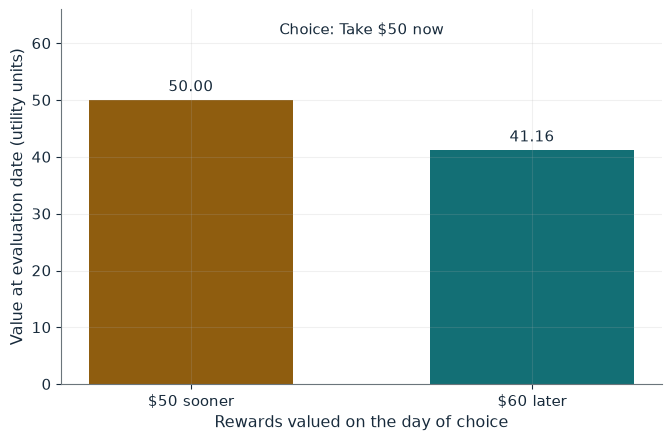

Value of $50        50.00
Value of $60        41.16
Choice              Take $50 now
Gap, $60 minus $50  -8.84

Worked steps:
  1. V50 = 50, received now
  2. V60 = 0.70 x 0.98 x 60 = 41.16
  3. 50.00 > 41.16, so the person takes the $50 now

On the day, 50 now beats 0.70 x 0.98 x 60 = 41.16, so the person takes the $50 and reverses the plan made a week earlier.


In [2]:
show(reversal_picture(beta=0.7, view='day'))

Change one input, `beta`, and hold the others at the book's values:

In [3]:
sweep(reversal_picture, 'beta', [0.5, 0.7, 0.85, 1.0], {'view': 'day'}, ['Value of $60', 'Choice'])

beta | Value of $60 | Choice
0.5 | 29.40 | Take $50 now
0.7 | 41.16 | Take $50 now
0.85 | 49.98 | Take $50 now
1.0 | 58.80 | Wait for $60


The plan made a week ahead (wait, 40.3368 > 34.30) reverses on the day because 50 > 41.16. At $\beta=0.85$ the later reward is worth 49.98, a near tie that still favours the \$50; with $\beta=1$ it is worth $0.98(60)=58.80$ and the person waits. A commitment device is worth up to 40.3368 - 34.30 = 6.0368.

## 2. Hot-cold empathy gap: packing lunch in a cold state

Packing costs \$6, the late vendor charges \$15, and the meal is actually worth \$20 at hour seven. Forecasting only \$5, the worker packs nothing and buys late:

$$20-15=5, \qquad 20-6=14, \qquad 14-5=9.$$

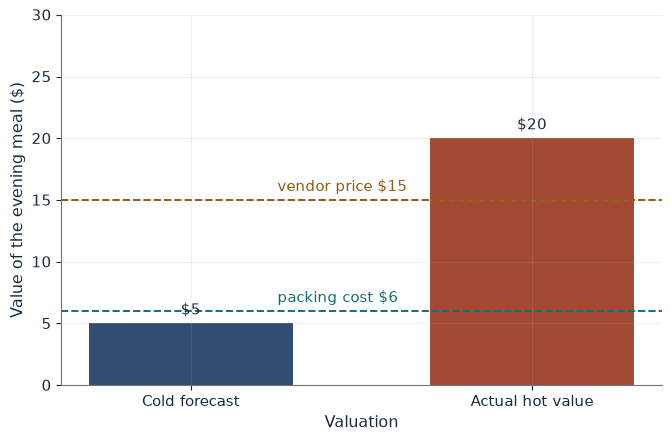

Plan                        Pack nothing, buy late
Realized surplus ($)        5
Best-plan surplus ($)       14
Cost of forecast error ($)  9

Worked steps:
  1. Forecast 5 < packing cost 6, so the worker packs nothing
  2. Late purchase: 20 - 15 = 5
  3. Best plan with an accurate forecast: pack, 20 - 6 = 14
  4. Cost of the forecast error = 14 - 5 = 9

Forecast 5 < packing cost 6, so the worker packs nothing. Late purchase: 20 - 15 = 5. Best plan with an accurate forecast: pack, 20 - 6 = 14. Cost of the forecast error = 14 - 5 = 9.


In [4]:
show(lunch_picture(forecast=5, hot=20))

Change one input, `forecast`, and hold the others at the book's values:

In [5]:
sweep(lunch_picture, 'forecast', [5, 8, 12], {'hot': 20}, ['Plan', 'Realized surplus ($)', 'Cost of forecast error ($)'])

forecast | Plan | Realized surplus ($) | Cost of forecast error ($)
5 | Pack nothing, buy late | 5 | 9
8 | Pack the meal | 14 | 0
12 | Pack the meal | 14 | 0


The error costs 9, not the full \$15 vendor price, because the late meal is still worth buying. Any forecast above \$6 (8 or the prompted 12) leads to packing and removes the loss.

## 3. Temptation and self-control: paying for a smaller menu

$$W(A)=\max_{x\in A}\{u(x)+v(x)\}-\max_{y\in A}v(y)$$

With $u(f)=10$, $u(c)=4$, $v(f)=0$ and $v(c)=5$: $W(\{f\})=10$ and $W(B)=\max\{10,9\}-\max\{0,5\}=10-5=5$.

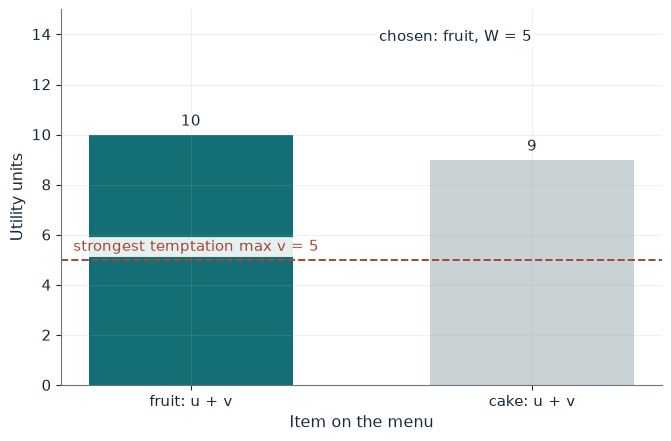

Choice                  Fruit
Menu welfare W          5
Self-control cost       5
Loss versus commitment  5

Worked steps:
  1. Fruit: u + v = 10 + 0 = 10
  2. Cake: u + v = 4 + 5 = 9
  3. Choice: fruit, since 10 > 9
  4. W = max(10, 9) - max(0, 5) = 10 - 5 = 5

Cake's combined utility 4 + 5 = 9 is below fruit's 10, so the diner resists and eats fruit. Menu welfare is 10 - 5 = 5: the same fruit as under commitment, but 5 units of self-control cost.


In [6]:
show(menu_picture(vc=5, menu='full'))

Change one input, `vc`, and hold the others at the book's values:

In [7]:
sweep(menu_picture, 'vc', [2, 5, 8], {'menu': 'full'}, ['Choice', 'Menu welfare W', 'Self-control cost'])

vc | Choice | Menu welfare W | Self-control cost
2 | Fruit | 8 | 2
5 | Fruit | 5 | 5
8 | Cake | 4 | 0


At $v(c)=5$ the diner still eats fruit but loses 5 units to self-control. At $v(c)=8$ cake's combined utility $4+8=12$ beats fruit and $W(B)=12-8=4$. The commitment menu is worth 10 in every case.

## 4. Projection bias: ordering dessert while hungry

Predicted value mixes the true Sunday value 2 with the current value:

$$\widehat u=(1-0.50)(2)+0.50(8)=5.$$

Each dessert costs \$4 and the package holds two.

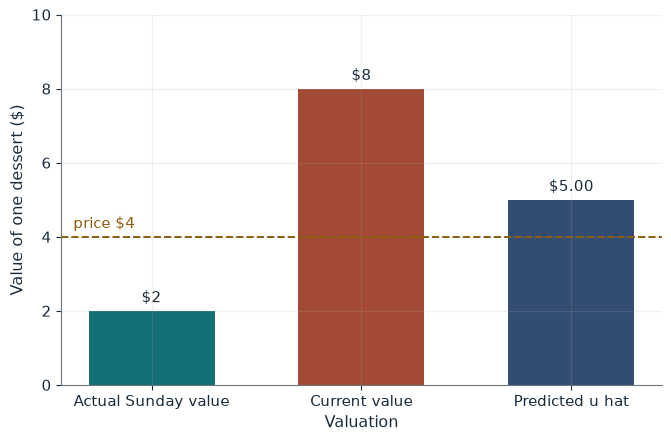

Predicted value u hat ($)  5.00
Order                      Two desserts
Realized gain ($)          -4.00

Worked steps:
  1. u hat = (1 - 0.50) x 2 + 0.50 x 8 = 5.00
  2. 5.00 > 4.00, so she orders the two-dessert package
  3. Realized gain = 2 x 2 - 2 x 4 = -4.00

Ordering while hungry before lunch, her current value is $8. Predicted value is (1 - 0.50) x 2 + 0.50 x 8 = 5.00. 5.00 > 4.00, so she orders the two-dessert package. On Sunday the pair is worth 4 and costs 8, a loss of 4.00.


In [8]:
show(dessert_picture(alpha=0.5, state='hungry'))

Change one input, `alpha`, and hold the others at the book's values:

In [9]:
sweep(dessert_picture, 'alpha', [0, 0.25, 0.5, 0.75], {'state': 'hungry'}, ['Predicted value u hat ($)', 'Order', 'Realized gain ($)'])

alpha | Predicted value u hat ($) | Order | Realized gain ($)
0 | 2.00 | None | 0.00
0.25 | 3.50 | None | 0.00
0.5 | 5.00 | Two desserts | -4.00
0.75 | 6.50 | Two desserts | -4.00


Hungry, she predicts 5 > 4 and orders two desserts, losing $2(2)-2(4)=-4$. After lunch (`state='fed'`) the forecast is $(1-0.50)(2)+0.50(2)=2$ and she declines.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

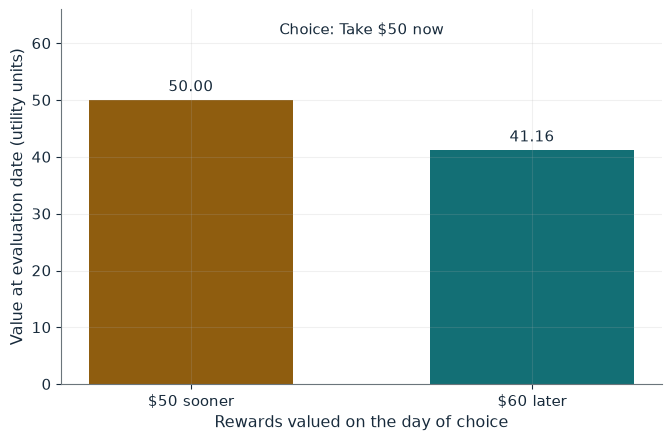

Value of $50        50.00
Value of $60        41.16
Choice              Take $50 now
Gap, $60 minus $50  -8.84

Worked steps:
  1. V50 = 50, received now
  2. V60 = 0.70 x 0.98 x 60 = 41.16
  3. 50.00 > 41.16, so the person takes the $50 now

On the day, 50 now beats 0.70 x 0.98 x 60 = 41.16, so the person takes the $50 and reverses the plan made a week earlier.


In [10]:
show(reversal_picture(beta=0.7, view='day'))

## Practice

**1.** What is the largest beta at which the day-of choice still takes the \$50?

<details><summary>Answer</summary>

Switch when 50 > beta x 0.98 x 60 = 58.8 beta, so beta < 50 / 58.8 = 0.8503. At beta = 0.85 the \$60 is worth 49.98, so the person still switches, barely.

</details>

**2.** If the hot value were \$12 and the forecast \$5, what is the cost of the forecast error?

<details><summary>Answer</summary>

Late purchase gives 12 - 15 < 0, so the worker buys nothing (0). Packing would give 12 - 6 = 6. Cost 6 - 0 = 6.

</details>

**3.** With current value 8, what alpha makes the predicted value equal the \$4 price?

<details><summary>Answer</summary>

2 + 6 alpha = 4, so alpha = 1/3.

</details>